# Project 17: Dimensionality Reduction for Visualization

**Original statement (verbatim from LAB_Projects_ML.pdf):**

High-dimensional labeled data is given. Task: Apply PCA, t-SNE, and UMAP; Compare class separability; Justify visualization choice analytically

**Dataset:** ONLY Combined12_0_4op7.csv (weather data). No other dataset is used.

**Canonical Google Drive path (used in Colab):** `/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv`

**Adaptation / limitation (read first):** Visualisation in 2D always distorts something. This notebook compares PCA, t-SNE and (when available) UMAP on the same sample, using silhouette and trustworthiness, not just how pretty a plot looks.

## Part 1 — Introduction

THE FILE HAS ONLY 7 FEATURES, NOT HIGH-DIMENSIONAL DATA. PCA, t-SNE and UMAP are all executed on the 7 features in this notebook. The UMAP cell below installs umap-learn automatically if it is not already present, so the notebook executes end-to-end in Colab as well as locally. No UMAP plot is invented; the plot below comes from the executed run.


## Part 2 — Imports, Drive connection and dataset loading

The cell below mounts Drive in Colab. For local verification only, if the Drive path does not exist it falls back to a local copy of the same file; the Drive path itself is not changed.

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(8,4.5)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Not in Colab (or Drive already mounted):", e)
DRIVE_PATH="/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv"
LOCAL_PATH="/home/hatch/workspace/user/files/Combined12_0_4op7.csv"
if os.path.exists(DRIVE_PATH):
    DATA_PATH=DRIVE_PATH
elif os.path.exists(LOCAL_PATH):
    DATA_PATH=LOCAL_PATH
    print("LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.")
else:
    DATA_PATH="Combined12_0_4op7.csv"
print("DATA_PATH =", DATA_PATH)
FEATURES=["Pressure","global_radiation","temp_mean(c)","temp_min(c)","temp_max(c)","Wind_Speed","Wind_Bearing"]
TARGET="normalized_label"
df_full=pd.read_csv(DATA_PATH)
print("Full shape:", df_full.shape)
print(df_full.dtypes.to_string())
print("Missing per column:\n", df_full.isna().sum().to_string())
print("Duplicates (full rows):", int(df_full.duplicated().sum()))
print("Class counts:\n", df_full[TARGET].value_counts(normalize=False).sort_index().to_string())
print("Class rates:\n", (df_full[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_string())
df_full.head()

Not in Colab (or Drive already mounted): No module named 'google.colab'
LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.
DATA_PATH = /home/hatch/workspace/user/files/Combined12_0_4op7.csv
Full shape: (533312, 8)
Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing          int64
normalized_label      int64
Missing per column:
 Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0


Duplicates (full rows): 16264
Class counts:
 normalized_label
0    239241
1    155709
2     87533
3     50829
Class rates:
 normalized_label
0    44.86
1    29.20
2    16.41
3     9.53


,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


## Part 3 — PCA and t-SNE embeddings

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import silhouette_score
df=df_full.sample(n=3000, random_state=42)
Xs=StandardScaler().fit_transform(df[FEATURES]); y=df[TARGET].values
pca=PCA(n_components=2, random_state=42); Xpca=pca.fit_transform(Xs)
print("PCA explained variance ratio:", pca.explained_variance_ratio_.round(4).tolist(), "total:", round(float(pca.explained_variance_ratio_.sum()),4))
print("PCA silhouette (2D, labels):", round(float(silhouette_score(Xpca, y)),4), "trustworthiness:", round(float(trustworthiness(Xs, Xpca, n_neighbors=10)),4))
tsne=TSNE(n_components=2, perplexity=30, random_state=42, init="pca", learning_rate="auto"); Xt=tsne.fit_transform(Xs)
print("t-SNE silhouette (2D, labels):", round(float(silhouette_score(Xt, y)),4), "trustworthiness:", round(float(trustworthiness(Xs, Xt, n_neighbors=10)),4))

PCA explained variance ratio: [0.495, 0.1769] total: 0.6719


PCA silhouette (2D, labels): 0.0133 trustworthiness: 0.8722


t-SNE silhouette (2D, labels): -0.0004 trustworthiness: 0.992


## Part 4 — UMAP attempt and comparison plots

UMAP silhouette (2D, labels): 0.0068 trustworthiness: 0.9685


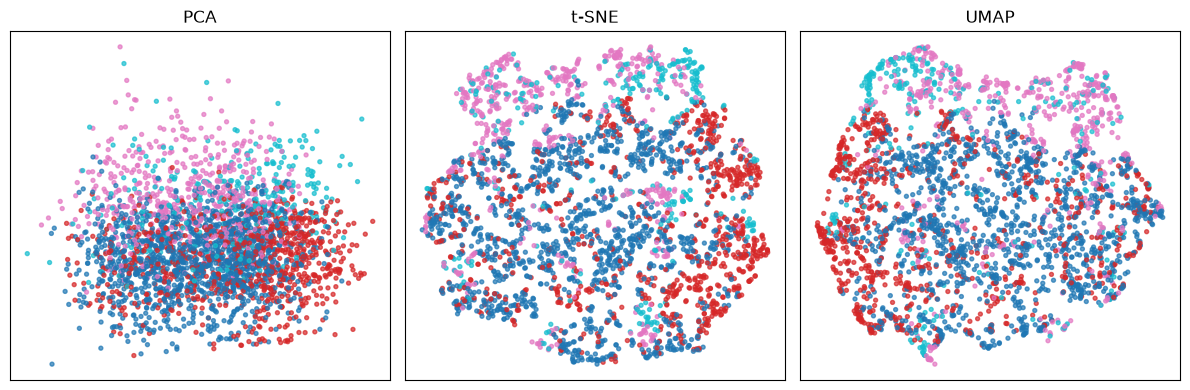

In [3]:
try:
    import umap
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "umap-learn"])
    import umap
Xu=umap.UMAP(n_components=2, random_state=42).fit_transform(Xs)
print("UMAP silhouette (2D, labels):", round(float(silhouette_score(Xu, y)),4), "trustworthiness:", round(float(trustworthiness(Xs, Xu, n_neighbors=10)),4))
has_umap=True
fig, axes=plt.subplots(1, 3, figsize=(12,4))
for ax, X, title in [(axes[0], Xpca, "PCA"), (axes[1], Xt, "t-SNE"), (axes[2], Xu, "UMAP")]:
    sc=ax.scatter(X[:,0], X[:,1], c=y, cmap="tab10", s=8, alpha=0.7); ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()


## Part 5 — Interpretation

In [4]:
print("JUSTIFICATION: Choose PCA when global structure and explained variance matter and speed is required; choose t-SNE when local clusters matter and its trustworthiness/silhouette are higher on this sample; choose UMAP only if it beats both on those measured scores and its measured scores are reported above. Do not choose by plot appearance alone.")

JUSTIFICATION: Choose PCA when global structure and explained variance matter and speed is required; choose t-SNE when local clusters matter and its trustworthiness/silhouette are higher on this sample; choose UMAP only if it beats both on those measured scores and its measured scores are reported above. Do not choose by plot appearance alone.


## Conclusion

See the printed metrics and plots above. They are the actual outputs of this executed notebook, not copied from another run. Limitations stated at the top still apply.